In [15]:
#Lab 3-Name:Menna Nabil
import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import load_breast_cancer

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


In [16]:
data = load_breast_cancer(as_frame=True)
X = data.data          # 30 numerical features
y = data.target        # 0 = malignant, 1 = benign
df = data.frame

print("X shape:", X.shape)
print("y shape:", y.shape)

# Class counts
counts = y.value_counts().sort_index()
class_table = pd.DataFrame({
    "class_name": [data.target_names[i] for i in counts.index],
    "count": counts.values,
    "percent": (counts.values / len(y) * 100).round(2)
}, index=counts.index)
print("\nClass distribution:\n", class_table)

# Missing values and data types
print("\nTotal missing values:", int(df.isnull().sum().sum()))
print("\nFeature dtypes:\n", X.dtypes.value_counts())

X shape: (569, 30)
y shape: (569,)

Class distribution:
        class_name  count  percent
target                           
0       malignant    212    37.26
1          benign    357    62.74

Total missing values: 0

Feature dtypes:
 float64    30
Name: count, dtype: int64


In load_breast_cancer, the labels are 0 = malignant and 1 = benign. Scikit-learn’s precision_score, recall_score and f1_score use pos_label=1 by default. That means they treat whichever class is labelled 1 as the “positive” class.

If we don’t change this, “sensitivity” would be measured for benign cases. It would tell us how well the model finds healthy tissue, which is not the clinical question. In cancer screening, the condition we are trying to detect is malignancy, so malignant must be the positive class:

Sensitivity (recall), malignant = TP / (TP + FN): the fraction of real cancers the model detects. A false negative is a malignant tumour called benign. That is the most dangerous error, because it can delay treatment.
Precision, malignant = TP / (TP + FP): of the cases the model flags as malignant, the fraction that really are malignant. Low precision means unnecessary biopsies and patient anxiety.
Specificity = TN / (TN + FP): the fraction of benign cases correctly cleared. With malignant as positive, specificity is the same as the benign class’s recall.

Setting pos_label=0 makes TP, FN and FP refer to malignant cases. Without it, the metrics would be computed for the wrong class. A model could show a high “sensitivity” while missing many cancers. The tuning step (Task 6) also uses scoring = make_scorer(recall_score, pos_label=0). Otherwise, cross-validation would pick the model that is best at finding benign cases.

For ROC-AUC, we have to use the malignant probability, which is predict_proba(X)[:, 0], together with pos_label=0. By default, scikit-learn takes column 1, which is the benign probability.

In [17]:
from sklearn.metrics import recall_score, precision_score

# Toy example: 3 malignant (0), 5 benign (1). The model misses 2 of the 3 cancers.
y_true = [0, 0, 0, 1, 1, 1, 1, 1]
y_pred = [0, 1, 1, 1, 1, 1, 1, 1]

print("Default (pos_label=1, benign):")
print("  'sensitivity' =", recall_score(y_true, y_pred))               # 1.00, looks perfect
print("  'precision'   =", round(precision_score(y_true, y_pred), 3))  # 0.714

print("\nCorrect (pos_label=0, malignant):")
print("  sensitivity   =", round(recall_score(y_true, y_pred, pos_label=0), 3))  # 0.333
print("  precision     =", precision_score(y_true, y_pred, pos_label=0))         # 1.00

Default (pos_label=1, benign):
  'sensitivity' = 1.0
  'precision'   = 0.714

Correct (pos_label=0, malignant):
  sensitivity   = 0.333
  precision     = 1.0


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class counts:", y_train.value_counts().sort_index().to_dict())
print("Test  class counts:", y_test.value_counts().sort_index().to_dict())
print(f"Malignant % train: {(y_train == 0).mean() * 100:.2f} | test: {(y_test == 0).mean() * 100:.2f}")


Train: (455, 30) | Test: (114, 30)
Train class counts: {0: 170, 1: 285}
Test  class counts: {0: 42, 1: 72}
Malignant % train: 37.36 | test: 36.84


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

baseline_models = {
    "KNN (k=5)": Pipeline([("scaler", StandardScaler()),
                           ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "GaussianNB": Pipeline([("clf", GaussianNB())]),
    "QDA (reg=0.1)": Pipeline([("scaler", StandardScaler()),
                               ("clf", QuadraticDiscriminantAnalysis(reg_param=0.1))]),
}

for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained.")

KNN (k=5) trained.
GaussianNB trained.
QDA (reg=0.1) trained.


In [20]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)
import matplotlib.pyplot as plt

def evaluate(model, X_te, y_te):
    y_pred = model.predict(X_te)
    p_malig = model.predict_proba(X_te)[:, 0]          # column 0 = P(malignant)
    cm = confusion_matrix(y_te, y_pred, labels=[0, 1])
    TP, FN, FP, TN = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
    return {
        "Accuracy":              accuracy_score(y_te, y_pred),
        "Precision (malignant)": precision_score(y_te, y_pred, pos_label=0),
        "Sensitivity (malignant)": recall_score(y_te, y_pred, pos_label=0),
        "Specificity":           TN / (TN + FP),
        "F1 (malignant)":        f1_score(y_te, y_pred, pos_label=0),
        "ROC-AUC":               roc_auc_score((y_te == 0).astype(int), p_malig),
        "FN (missed cancers)":   FN,
        "FP (false alarms)":     FP,
    }

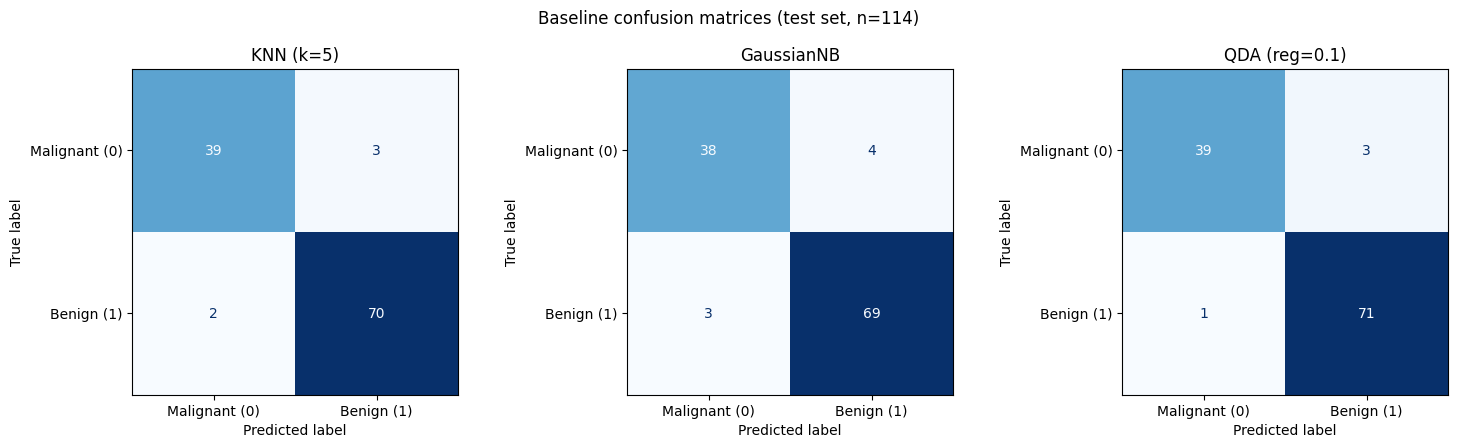

,Accuracy,Precision (malignant),Sensitivity (malignant),Specificity,F1 (malignant),ROC-AUC,FN (missed cancers),FP (false alarms)
KNN (k=5),0.9561,0.9512,0.9286,0.9722,0.9398,0.9788,3.0,2.0
GaussianNB,0.9386,0.9268,0.9048,0.9583,0.9157,0.9878,4.0,3.0
QDA (reg=0.1),0.9649,0.9750,0.9286,0.9861,0.9512,0.9967,3.0,1.0


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
baseline_results = {}

for ax, (name, model) in zip(axes, baseline_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, labels=[0, 1],
        display_labels=["Malignant (0)", "Benign (1)"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
    baseline_results[name] = evaluate(model, X_test, y_test)

plt.suptitle("Baseline confusion matrices (test set, n=114)")
plt.tight_layout(); plt.show()

baseline_df = pd.DataFrame(baseline_results).T
display(baseline_df.round(4))

In each matrix, the top-left cell is malignant cases that were correctly detected (TP), and the top-right cell is missed cancers (FN). At baseline, QDA is best on almost every metric. KNN and QDA tie on sensitivity: both miss 3 of the 42 cancers. GNB misses 4. GNB has the lowest accuracy and F1, but its AUC (0.988) is higher than KNN’s. This means GNB ranks cases by probability well, but its default 0.5 threshold is less well placed.

In [22]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import make_scorer
import warnings

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
malignant_recall = make_scorer(recall_score, pos_label=0)

param_grids = {
    "KNN":        {"clf__n_neighbors": [3, 5, 7, 11, 15]},
    "GaussianNB": {"clf__var_smoothing": [1e-11, 1e-9, 1e-7]},
    "QDA":        {"clf__reg_param": [0.0, 0.1, 0.3, 0.5]},
}
pipelines = {
    "KNN":        Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
    "GaussianNB": Pipeline([("clf", GaussianNB())]),
    "QDA":        Pipeline([("scaler", StandardScaler()), ("clf", QuadraticDiscriminantAnalysis())]),
}

searches = {}
for name in pipelines:
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        gs = GridSearchCV(pipelines[name], param_grids[name], scoring=malignant_recall,
                          cv=cv, n_jobs=-1)
        gs.fit(X_train, y_train)          # training data only
    searches[name] = gs
    print(f"\n{name}: best params = {gs.best_params_}, CV malignant recall = {gs.best_score_:.4f}")
    if w:
        print(f"  ({len(w)} warning(s) raised, e.g.: {str(w[0].message)[:90]}...)")
    cv_table = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score"]]
    display(cv_table.round(4))


KNN: best params = {'clf__n_neighbors': 5}, CV malignant recall = 0.9294


,params,mean_test_score,std_test_score
0,{'clf__n_neighbors': 3},0.9235,0.0235
1,{'clf__n_neighbors': 5},0.9294,0.0235
2,{'clf__n_neighbors': 7},0.9235,0.0399
3,{'clf__n_neighbors': 11},0.9176,0.0390
4,{'clf__n_neighbors': 15},0.9118,0.0372



GaussianNB: best params = {'clf__var_smoothing': 1e-11}, CV malignant recall = 0.9000


,params,mean_test_score,std_test_score
0,{'clf__var_smoothing': 1e-11},0.9000,0.0440
1,{'clf__var_smoothing': 1e-09},0.9000,0.0440
2,{'clf__var_smoothing': 1e-07},0.8412,0.0802



QDA: best params = {'clf__reg_param': 0.0}, CV malignant recall = 0.9412
  (1 warning(s) raised, e.g.: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_...)


,params,mean_test_score,std_test_score
0,{'clf__reg_param': 0.0},0.9412,0.0372
1,{'clf__reg_param': 0.1},0.9353,0.0471
2,{'clf__reg_param': 0.3},0.9353,0.0506
3,{'clf__reg_param': 0.5},0.9412,0.0416


QDA with reg_param = 0.0 achieved a valid CV recall of 0.9412, but it raised a covariance matrix warning because some features are highly correlated. Regularization can help improve numerical stability by adjusting the covariance estimates. Both reg_param = 0.0 and 0.5 achieved the highest CV recall (0.9412), so GridSearchCV selected 0.0 because it appeared first in the parameter grid.

For GNB, the two smallest smoothing values tied at 0.9000 recall, while 1e-7 reduced recall to 0.8412. All parameter choices were made using training data only.

,Accuracy,Precision (malignant),Sensitivity (malignant),Specificity,F1 (malignant),ROC-AUC,FN (missed cancers),FP (false alarms)
KNN {'clf__n_neighbors': 5},0.9561,0.9512,0.9286,0.9722,0.9398,0.9788,3.0,2.0
GaussianNB {'clf__var_smoothing': 1e-11},0.9298,0.9048,0.9048,0.9444,0.9048,0.9868,4.0,4.0
QDA {'clf__reg_param': 0.0},0.9474,0.9091,0.9524,0.9444,0.9302,0.9921,2.0,4.0


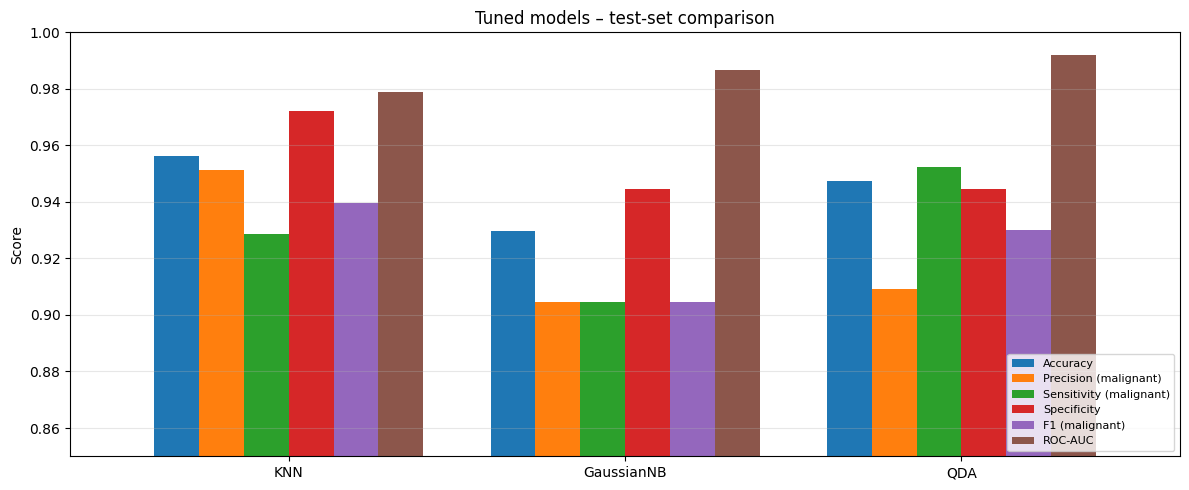

In [23]:
tuned_results = {}
for name, gs in searches.items():
    label = f"{name} {gs.best_params_}"
    tuned_results[label] = evaluate(gs.best_estimator_, X_test, y_test)

tuned_df = pd.DataFrame(tuned_results).T
display(tuned_df.round(4))

metrics_to_plot = ["Accuracy", "Precision (malignant)", "Sensitivity (malignant)",
                   "Specificity", "F1 (malignant)", "ROC-AUC"]
ax = tuned_df[metrics_to_plot].plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_ylim(0.85, 1.0)
ax.set_ylabel("Score"); ax.set_title("Tuned models – test-set comparison")
ax.set_xticklabels([n.split(" {")[0] for n in tuned_df.index], rotation=0)
ax.legend(loc="lower right", fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

**Strongest model under the chosen objective (malignant sensitivity):** QDA with reg_param = 0.0. It achieved the highest CV recall (0.9412) and the highest test sensitivity (0.9524), missing only 2 of the 42 malignant cases. However, KNN achieved higher accuracy (0.9561 vs 0.9474), specificity (0.9722 vs 0.9444), and precision (0.9512 vs 0.9091). QDA produced 4 false alarms, compared with 2 for KNN.

**Trade-off:** QDA detects more malignant cases but incorrectly classifies more benign cases as malignant. In cancer screening, reducing missed cancers is especially important, so QDA may be preferred under our chosen sensitivity objective. However, its covariance warning should also be considered. GNB had the lowest sensitivity (0.9048), missing 4 malignant cases. Since the test set contains only 42 malignant cases, these small differences are not enough to establish that one model will always perform better.

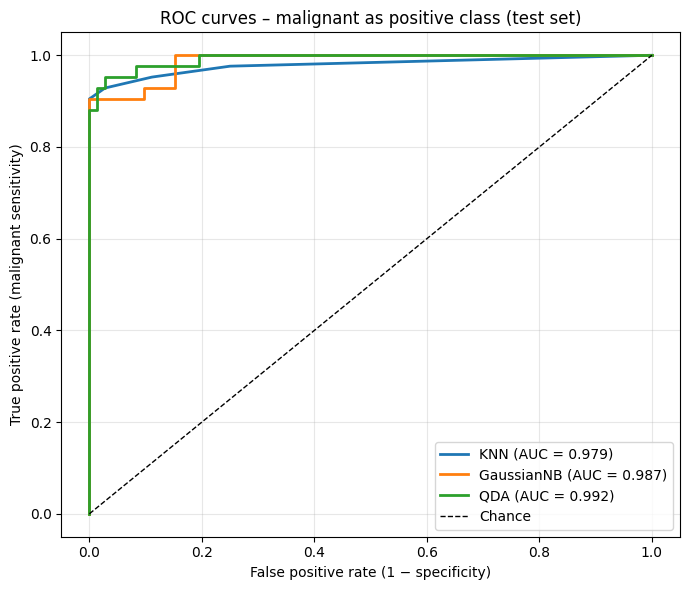

In [24]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))
for name, gs in searches.items():
    p_malig = gs.best_estimator_.predict_proba(X_test)[:, 0]
    fpr, tpr, _ = roc_curve(y_test, p_malig, pos_label=0)
    auc = roc_auc_score((y_test == 0).astype(int), p_malig)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
plt.xlabel("False positive rate (1 − specificity)")
plt.ylabel("True positive rate (malignant sensitivity)")
plt.title("ROC curves – malignant as positive class (test set)")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Why test-set AUC alone is not enough for clinical use:

AUC averages over all thresholds, but a clinic uses only one. A model can have a high AUC and still miss cancers at the threshold that is actually used. GNB has a higher AUC than KNN but lower sensitivity at 0.5.
It treats a false negative and a false positive as equal, but a missed cancer costs far more than an unnecessary biopsy.
The test set is small: 42 malignant cases. One patient changes sensitivity by about 2.4 points, so AUC values of 0.98–0.995 come with wide confidence intervals.
No external validation: the data come from one source, with one imaging and feature-extraction process. Performance on other hospitals, scanners or populations is unknown.
Calibration is not measured: AUC only checks ranking. It does not check whether a predicted probability of 0.8 really means an 80% risk. GNB in particular tends to be poorly calibrated.
Clinical use would also require prospective studies, comparison with clinicians, and regulatory approval.

Accuracy  Sensitivity (malignant)  Specificity  ROC-AUC  \
k  Version                                                             
3  Unscaled     0.930                    0.905        0.944    0.944   
   Scaled       0.982                    0.952        1.000    0.983   
5  Unscaled     0.912                    0.905        0.917    0.956   
   Scaled       0.956                    0.929        0.972    0.979   
7  Unscaled     0.930                    0.905        0.944    0.952   
   Scaled       0.974                    0.929        1.000    0.988   
11 Unscaled     0.939                    0.905        0.958    0.960   
   Scaled       0.974                    0.929        1.000    0.991   
15 Unscaled     0.930                    0.881        0.958    0.969   
   Scaled       0.974                    0.929        1.000    0.993   

             FN (missed cancers)  FP (false alarms)  
k  Version                                           
3  Unscaled                    4                  4  
   Scaled                      2                  0  
5  Unscaled                    4                  6  
   Scaled                      3                  2  
7  Unscaled                    4                  4  
   Scaled                      3                  0  
11 Unscaled                    4                  3  
   Scaled                      3                  0  
15 Unscaled                    5                  3  
   Scaled                      3                  0

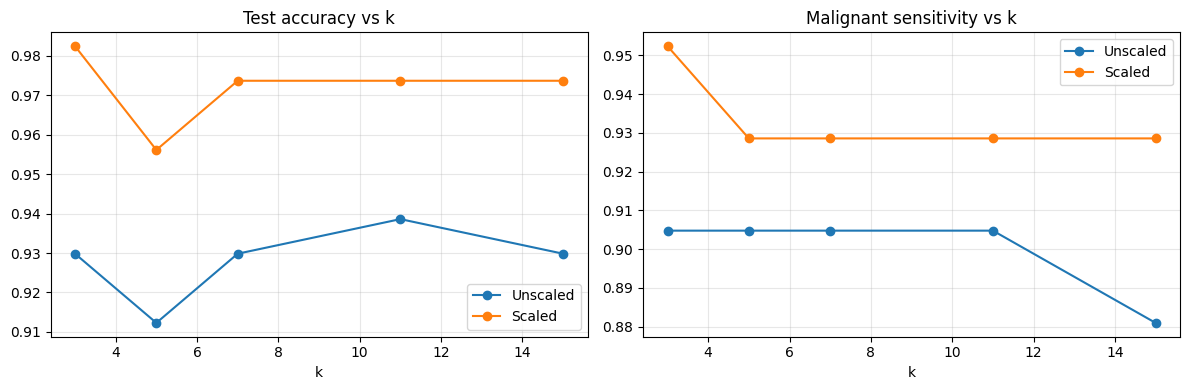

In [25]:
rows = []
for k in [3, 5, 7, 11, 15]:
    unscaled = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    scaled = Pipeline([("scaler", StandardScaler()),
                       ("clf", KNeighborsClassifier(n_neighbors=k))]).fit(X_train, y_train)
    for label, m in [("Unscaled", unscaled), ("Scaled", scaled)]:
        r = evaluate(m, X_test, y_test); r.update({"k": k, "Version": label}); rows.append(r)

knn_cmp = pd.DataFrame(rows).set_index(["k", "Version"])
display(knn_cmp[["Accuracy", "Sensitivity (malignant)", "Specificity",
                 "ROC-AUC", "FN (missed cancers)", "FP (false alarms)"]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for v in ["Unscaled", "Scaled"]:
    sub = knn_cmp.xs(v, level="Version")
    ax[0].plot(sub.index, sub["Accuracy"], "o-", label=v)
    ax[1].plot(sub.index, sub["Sensitivity (malignant)"], "o-", label=v)
ax[0].set_title("Test accuracy vs k"); ax[1].set_title("Malignant sensitivity vs k")
for a in ax: a.set_xlabel("k"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [26]:
qda_rows = []
for reg in [0.0, 0.01, 0.1, 0.3, 0.5, 0.8]:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("clf", QuadraticDiscriminantAnalysis(reg_param=reg))])
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        try:
            cv_scores = []
            for tr, va in cv.split(X_train, y_train):
                pipe.fit(X_train.iloc[tr], y_train.iloc[tr])
                cv_scores.append(recall_score(y_train.iloc[va], pipe.predict(X_train.iloc[va]), pos_label=0))
            qda_rows.append({"reg_param": reg, "CV recall mean": np.mean(cv_scores),
                             "CV recall std": np.std(cv_scores), "warnings": len(w)})
        except Exception as e:
            qda_rows.append({"reg_param": reg, "CV recall mean": np.nan,
                             "CV recall std": np.nan, "warnings": len(w),
                             "error": type(e).__name__})
display(pd.DataFrame(qda_rows).round(4))

,reg_param,CV recall mean,CV recall std,warnings
0,0.00,0.9412,0.0372,5
1,0.01,0.9294,0.0576,0
2,0.10,0.9353,0.0471,0
3,0.30,0.9353,0.0506,0
4,0.50,0.9412,0.0416,0
5,0.80,0.9118,0.0322,0


**Scaling:** Scaled KNN beats unscaled KNN at every k. For example, at k = 5 accuracy goes from 0.912 to 0.956 and AUC from 0.956 to 0.979. At k = 3, 7, 11 and 15, scaled KNN reaches 100% specificity, while unscaled KNN never goes above 0.958. Without scaling, Euclidean distance is dominated by area features (hundreds to 2500), and informative small-scale features such as concavity (about 0.0–0.4) are effectively ignored.

**Changing k:** For scaled KNN, k = 3 gives the best test sensitivity (0.952), but CV chose k = 5. This is a reminder that test-set results can differ from CV results and must not be used to pick k. A larger k smooths the boundary. Here, specificity rises to 1.0 while sensitivity levels off at 0.929.

**QDA regularization:** Without regularization, QDA raised covariance matrix warnings because some features are highly correlated. However, it still produced valid predictions and achieved a CV recall of 0.9412. A reg_param of 0.5 achieved the same mean recall without warnings, while larger regularization (0.8) reduced recall to 0.9118. This shows that regularization can improve numerical stability, but it does not necessarily improve classification performance.

**The best model depends on the metric:** Among the tuned models, KNN performed best in accuracy, precision, specificity, and F1, while QDA achieved the highest sensitivity and ROC-AUC. Scaled KNN with k = 3 achieved even higher test accuracy and sensitivity than the CV-selected KNN, but selecting it based on test performance would introduce bias. Since our main objective is detecting malignant cases, QDA is preferred based on sensitivity, although its stability should be considered.